# Issue 12: Comprobación temporal por cohortes

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/J-D-Rosales/Prediction-With-Machine-Learning-Lending-Club/blob/main/notebooks/issue12.ipynb)

La sección 10 de la propuesta promete medir la madurez de las cohortes antes de decidir un corte cronológico. La partición del proyecto es aleatoria (64/16/20, `src/data.py`); este notebook comprueba si el modelo final sigue funcionando cuando se entrena con el pasado y se evalúa con el futuro.

1. **Madurez por cohorte:** con el archivo completo (incluidos `Current` y atrasados), qué proporción de cada año de emisión y plazo ya tiene resultado definitivo, y su tasa de `Charged Off`.
2. **Corte cronológico:** el último año con al menos 90 % de préstamos resueltos.
3. **Prueba de estabilidad:** el gradient boosting del modelo final (misma configuración que `03_modelo_final.ipynb`) entrenado solo con cohortes anteriores al año evaluado, frente a uno entrenado con una muestra aleatoria del mismo tamaño que sí ve todos los años.
4. **ROC-AUC por año de emisión** dentro de validación, con el modelo entrenado en la partición aleatoria.

**Reglas:** el conjunto de prueba no se usa (ya se evaluó una sola vez en el modelo final). Los modelos se entrenan con préstamos de la partición de entrenamiento y se evalúan con préstamos de validación. Todo lo que se aprende (codificación de categóricas) se ajusta solo con los préstamos de entrenamiento de cada experimento. `issue_d` no es predictor.

**Preprocesamiento:** se parte de las variables de la base común después del Issue 3, sin la imputación ni el escalado de los issues 5 y 6, porque esos estadísticos se aprendieron con préstamos de todos los años. `HistGradientBoostingClassifier` maneja los nulos de forma nativa y los árboles no necesitan escalado ni `log1p` (son transformaciones monótonas), así que el modelo es equivalente y no entra ningún estadístico del futuro.

**Colab:** la primera celda clona el repositorio y descarga los datos de Kaggle con `kagglehub`. En local no hace nada. Hace falta un entorno con unos 12 GB de RAM (el Colab gratuito alcanza). Tarda unos 20 minutos.


In [1]:
# Preparación del entorno: en Colab clona el repositorio y descarga los datos; en local no hace nada.
import os
import sys
from pathlib import Path

EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:
    import subprocess
    RAIZ_REPO = Path('/content/Prediction-With-Machine-Learning-Lending-Club')
    if not RAIZ_REPO.exists():
        subprocess.run(['git', 'clone', '--depth', '1',
                        'https://github.com/J-D-Rosales/Prediction-With-Machine-Learning-Lending-Club.git',
                        str(RAIZ_REPO)], check=True)
    os.chdir(RAIZ_REPO / 'notebooks')
    destino = RAIZ_REPO / 'data' / 'accepted_2007_to_2018Q4.csv.gz'
    if not destino.exists():
        # Dataset público de Kaggle. Si kagglehub pide credenciales, ejecutar antes kagglehub.login(),
        # o copiar el archivo desde Google Drive a la ruta `destino`.
        import kagglehub
        carpeta = Path(kagglehub.dataset_download('wordsforthewise/lending-club'))
        origen = next(p for p in carpeta.rglob('*')
                      if p.is_file() and p.name.lower() == 'accepted_2007_to_2018q4.csv.gz')
        destino.symlink_to(origen)
    print('Datos en', destino)

sys.path.append('..')

In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.preprocessing import OneHotEncoder

from src.data import (COLUMNA_FECHA, COLUMNA_PARTICION, ESTADOS_TARGET, SEED,
                      cargar_prestamos, ruta_datos, separar_X_y)

pd.set_option('display.width', 200)

DIR_FIGURAS = Path.cwd().parent / 'reports' / 'figures'
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
AZUL, NARANJA, VERDE, TINTA, TINTA_2, REJILLA = '#2a78d6', '#eb6834', '#2f9e6e', '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'axes.edgecolor': TINTA_2,
    'axes.labelcolor': TINTA, 'xtick.color': TINTA_2, 'ytick.color': TINTA_2,
    'axes.grid': True, 'grid.color': REJILLA, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10,
    'axes.titlesize': 11, 'axes.titleweight': 'bold',
})

def guardar(fig, nombre):
    fig.savefig(DIR_FIGURAS / nombre, dpi=150, bbox_inches='tight')
    print(f'Figura guardada en reports/figures/{nombre}')

def metricas(y, prob):
    return {'ROC-AUC': roc_auc_score(y, prob), 'PR-AUC': average_precision_score(y, prob)}

## 1. Madurez por cohorte

La base común solo contiene préstamos resueltos, así que aquí se lee el archivo completo (solo `loan_status`, `issue_d` y `term`). Un préstamo está **resuelto** si su estado es `Fully Paid` o `Charged Off` (con o sin el prefijo "Does not meet the credit policy"); el resto (`Current`, `In Grace Period`, atrasados y `Default`) sigue abierto al cierre del archivo (2018 T4).

In [3]:
completo = pd.read_csv(ruta_datos(), usecols=['loan_status', 'issue_d', 'term'], low_memory=False)
completo = completo.dropna(subset=['issue_d'])
completo['año'] = pd.to_datetime(completo['issue_d'], format='%b-%Y').dt.year
completo['plazo'] = completo['term'].str.strip()
completo['resuelto'] = completo['loan_status'].isin(ESTADOS_TARGET.keys())
completo['charged_off'] = completo['loan_status'].map(ESTADOS_TARGET).eq(1)
print(f'Préstamos en el archivo completo: {len(completo):,}; resueltos: {completo["resuelto"].sum():,}')

def tabla_madurez(df):
    g = df.groupby('año')
    t = pd.DataFrame({'préstamos': g.size(), 'resueltos': g['resuelto'].sum()})
    t['% resueltos'] = 100 * t['resueltos'] / t['préstamos']
    t['tasa Charged Off (resueltos)'] = 100 * g['charged_off'].sum() / t['resueltos']
    return t

madurez = pd.concat({'36 months': tabla_madurez(completo[completo['plazo'] == '36 months']),
                     '60 months': tabla_madurez(completo[completo['plazo'] == '60 months']),
                     'ambos': tabla_madurez(completo)}, axis=1)
madurez.round(1)

Préstamos en el archivo completo: 2,260,668; resueltos: 1,348,059


36 months                                                    60 months                                                        ambos                                                   
     préstamos resueltos % resueltos tasa Charged Off (resueltos) préstamos resueltos % resueltos tasa Charged Off (resueltos) préstamos resueltos % resueltos tasa Charged Off (resueltos)
año                                                                                                                                                                                        
2007       603       603       100.0                         26.2       NaN       NaN         NaN                          NaN       603       603       100.0                         26.2
2008      2393      2393       100.0                         20.7       NaN       NaN         NaN                          NaN      2393      2393       100.0                         20.7
2009      5281      5281       100.0                         13.7       NaN       NaN         NaN                          NaN      5281      5281       100.0                         13.7
2010      9156      9156       100.0                         10.9    3381.0    3381.0       100.0                         22.4     12537     12537       100.0                         14.0
2011     14101     14101       100.0                         10.6    7620.0    7620.0       100.0                         23.6     21721     21721       100.0                         15.2
2012     43470     43470       100.0                         13.6    9897.0    9897.0       100.0                         27.7     53367     53367       100.0                         16.2
2013    100422    100422       100.0                         12.3   34392.0   34382.0       100.0                         25.1    134814    134804       100.0                         15.6
2014    162570    162570       100.0                         13.7   73059.0   60532.0        82.9                         31.1    235629    223102        94.7                         18.4
2015    283173    283026        99.9                         14.9  137922.0   92519.0        67.1                         36.4    421095    375545        89.2                         20.2
2016    323495    232353        71.8                         19.8  110912.0   60742.0        54.8                         36.4    434407    293095        67.5                         23.3
2017    320419    128538        40.1                         20.0  123160.0   40762.0        33.1                         32.9    443579    169300        38.2                         23.1
2018    344671     41268        12.0                         13.2  150571.0   15043.0        10.0                         22.6    495242     56311        11.4                         15.7

Figura guardada en reports/figures/temporal_madurez_cohortes.png


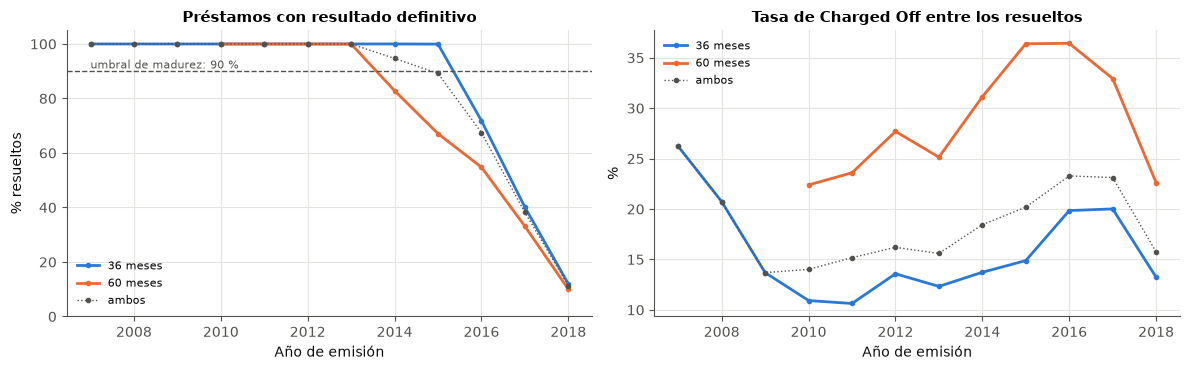

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
for plazo, color in (('36 months', AZUL), ('60 months', NARANJA), ('ambos', TINTA_2)):
    estilo = dict(color=color, marker='o', markersize=3, linewidth=2 if plazo != 'ambos' else 1,
                  linestyle='-' if plazo != 'ambos' else ':', label=plazo.replace('months', 'meses'))
    ax1.plot(madurez.index, madurez[(plazo, '% resueltos')], **estilo)
    ax2.plot(madurez.index, madurez[(plazo, 'tasa Charged Off (resueltos)')], **estilo)
ax1.axhline(90, color=TINTA_2, linestyle='--', linewidth=1)
ax1.text(2007, 91, 'umbral de madurez: 90 %', fontsize=8, color=TINTA_2)
ax1.set(title='Préstamos con resultado definitivo', xlabel='Año de emisión', ylabel='% resueltos', ylim=(0, 105))
ax2.set(title='Tasa de Charged Off entre los resueltos', xlabel='Año de emisión', ylabel='%')
for ax in (ax1, ax2):
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
guardar(fig, 'temporal_madurez_cohortes.png')
plt.show()

**Lectura:**

- **Las cohortes 2007–2013 están completas:** el 100 % de sus préstamos (ambos plazos) ya tiene resultado definitivo.
- **2014 y 2015 están maduras solo a 36 meses.** Los préstamos a 36 meses están resueltos en 100 % y 99.9 %; los de 60 meses, en 82.9 % y 67.1 %. En total, 94.7 % (2014) y 89.2 % (2015).
- **Desde 2016 las cohortes están lejos de terminar:** 67.5 % en 2016, 38.2 % en 2017 y 11.4 % en 2018. Lo que se resolvió antes de tiempo es una submuestra sesgada: prepagos e incumplimientos tempranos. Por eso la tasa de `Charged Off` a 60 meses parece llegar a 36.4 % en 2015–2016 y luego cae a 22.6 % en 2018: en 2018 casi solo hay prepagos.
- **El riesgo real sí cambia con el tiempo.** En las cohortes maduras a 36 meses, la tasa de `Charged Off` sube de 10.6 % (2011) a 14.9 % (2015). La población que el modelo ve no es estacionaria.
- **La base común incluye esas cohortes inmaduras:** 2016–2018 aportan 518,706 de los 1,348,059 préstamos resueltos (38.5 %). La partición aleatoria las mezcla con las maduras en entrenamiento, validación y prueba, así que las métricas del modelo final se calculan en parte sobre esta submuestra sesgada.

## 2. Corte cronológico

El corte es el último año de emisión en el que al menos el 90 % de los préstamos (ambos plazos) ya tiene resultado definitivo, siempre que todos los años anteriores también lo cumplan.

In [5]:
UMBRAL_MADUREZ = 90
maduros = madurez[('ambos', '% resueltos')] >= UMBRAL_MADUREZ
AÑO_CORTE = int(maduros[maduros.cummin()].index.max())
print(f'Último año maduro (≥ {UMBRAL_MADUREZ} % resueltos): {AÑO_CORTE}')
print('Último año maduro por plazo:',
      {p: int(madurez.index[madurez[(p, '% resueltos')] >= UMBRAL_MADUREZ].max()) for p in ('36 months', '60 months')})
del completo

Último año maduro (≥ 90 % resueltos): 2014
Último año maduro por plazo: {'36 months': 2015, '60 months': 2013}


**Corte elegido: 2014.** Es el último año con al menos 90 % de préstamos resueltos (94.7 %), y todos los anteriores llegan al 100 %. 2015 queda justo por debajo (89.2 %); se evalúa igualmente como primer año "futuro", porque su parte a 36 meses (67 % de sus préstamos) está completa, pero sus préstamos a 60 meses resueltos siguen sesgados hacia los que terminaron pronto. Por plazo, los cortes serían 2015 (36 meses) y 2013 (60 meses).

## 3. Datos para la prueba temporal

Se usan las mismas 69 variables que entran al modelo final: las que dejan los issues 2 (nulos > 90 %, casi constantes y texto libre) y 3 (redundantes), con `loan_amnt` incluida como en la cadena. Se codifican igual que en `03_modelo_final.ipynb` (one-hot con agrupación de categorías infrecuentes, `term_60`, años de empleo y antigüedad del historial crediticio en meses), pero el codificador se ajusta con los préstamos de entrenamiento de cada experimento.

In [6]:
# Las 69 variables que dejan los issues 2 y 3 (mismo orden que sus checkpoints; ver reports/decisiones_columnas.md).
COLUMNAS = ['loan_amnt', 'term', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'purpose',
            'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'fico_range_low', 'inq_last_6mths',
            'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util',
            'total_acc', 'collections_12_mths_ex_med', 'mths_since_last_major_derog', 'application_type',
            'tot_coll_amt', 'open_acc_6m', 'open_act_il', 'open_il_12m', 'open_il_24m', 'mths_since_rcnt_il',
            'il_util', 'open_rv_12m', 'open_rv_24m', 'max_bal_bc', 'all_util', 'total_rev_hi_lim', 'inq_fi',
            'total_cu_tl', 'inq_last_12m', 'acc_open_past_24mths', 'avg_cur_bal', 'bc_open_to_buy', 'bc_util',
            'mo_sin_old_il_acct', 'mo_sin_old_rev_tl_op', 'mo_sin_rcnt_rev_tl_op', 'mo_sin_rcnt_tl', 'mort_acc',
            'mths_since_recent_bc', 'mths_since_recent_bc_dlq', 'mths_since_recent_inq',
            'mths_since_recent_revol_delinq', 'num_accts_ever_120_pd', 'num_actv_bc_tl', 'num_actv_rev_tl',
            'num_bc_sats', 'num_bc_tl', 'num_il_tl', 'num_op_rev_tl', 'num_rev_accts', 'num_tl_90g_dpd_24m',
            'num_tl_op_past_12m', 'pct_tl_nvr_dlq', 'percent_bc_gt_75', 'pub_rec_bankruptcies', 'tax_liens',
            'tot_hi_cred_lim', 'total_bal_ex_mort', 'total_bc_limit', 'total_il_high_credit_limit']
CATEGORICAS = ['term', 'emp_length', 'home_ownership', 'verification_status', 'purpose',
               'addr_state', 'earliest_cr_line', 'application_type']
ONE_HOT = ['home_ownership', 'verification_status', 'purpose', 'addr_state', 'application_type']

base = cargar_prestamos()
X_base, y_base = separar_X_y(base, columnas=COLUMNAS)
NUMERICAS = [c for c in X_base.columns if c not in CATEGORICAS]
assert all(pd.api.types.is_numeric_dtype(X_base[c]) for c in NUMERICAS)
año = base[COLUMNA_FECHA].dt.year
particion = base[COLUMNA_PARTICION]

# Comprobación opcional contra el checkpoint del Issue 3, si existe (en Colab no está).
from src.checkpoints import DIR_CHECKPOINTS, existe_checkpoint
if existe_checkpoint('issue3'):
    import json
    tipos3 = json.loads((DIR_CHECKPOINTS / 'issue3' / '_tipos.json').read_text(encoding='utf-8'))
    assert list(tipos3['X_train']['dtypes']) == list(X_base.columns), 'columnas distintas al Issue 3'
    print('Columnas idénticas a las del checkpoint del Issue 3')

print(f'{X_base.shape[1]} variables ({len(NUMERICAS)} numéricas, {len(CATEGORICAS)} categóricas); {len(X_base):,} préstamos')
pd.crosstab(año, particion)

Columnas idénticas a las del checkpoint del Issue 3
69 variables (61 numéricas, 8 categóricas); 1,348,059 préstamos


particion,entrenamiento,validacion,prueba
issue_d,,,
2007,411,85,107
2008,1553,382,458
2009,3330,910,1041
2010,8008,2019,2510
2011,13932,3481,4308
2012,34237,8557,10573
2013,86337,21432,27035
2014,142965,35434,44703
2015,239843,60492,75210


In [7]:
def anios_empleo(s):
    s = s.str.strip().replace({'< 1 year': '0', '10+ years': '10'})
    return s.str.extract(r'(\d+)', expand=False).astype(float)

def meses_historial(earliest, ref):
    inicio = pd.to_datetime(earliest, format='%b-%Y')
    return ((ref.dt.year - inicio.dt.year) * 12 + (ref.dt.month - inicio.dt.month)).clip(lower=0).astype(float)

class Codificador:
    # Misma codificación que 03_modelo_final.ipynb; los nulos numéricos se dejan al modelo.
    # Las numéricas sin ningún valor observado en entrenamiento se descartan: en los modelos temporales,
    # las columnas que Lending Club empezó a registrar después (bloque de 2015-2016) aún no existían.
    def fit(self, X):
        self.numericas = [c for c in NUMERICAS if X[c].notna().any()]
        self.oh = OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=500,
                                sparse_output=False, dtype=np.float32).fit(X[ONE_HOT].astype(object))
        return self

    def transform(self, X):
        ref = base.loc[X.index, COLUMNA_FECHA]
        nuevas = pd.DataFrame({'term_60': (X['term'].str.strip() == '60 months').astype(float),
                               'emp_length_anios': anios_empleo(X['emp_length']),
                               'historial_meses': meses_historial(X['earliest_cr_line'], ref)}, index=X.index)
        oh = pd.DataFrame(self.oh.transform(X[ONE_HOT].astype(object)), index=X.index,
                          columns=self.oh.get_feature_names_out(ONE_HOT))
        return pd.concat([X[self.numericas].astype(np.float32), nuevas.astype(np.float32), oh], axis=1)

# Mejor configuración del modelo final (03_modelo_final.ipynb, sección 4).
CONF = dict(learning_rate=0.03, max_leaf_nodes=127, min_samples_leaf=2000, l2_regularization=0.0, max_features=0.8)

def entrenar(indices):
    # Ajusta el codificador y el gradient boosting solo con los préstamos de `indices`.
    inicio = time.time()
    cod = Codificador().fit(X_base.loc[indices])
    modelo = HistGradientBoostingClassifier(max_iter=1000, early_stopping=True, validation_fraction=0.1,
                                            n_iter_no_change=50, random_state=SEED, **CONF)
    modelo.fit(cod.transform(X_base.loc[indices]), y_base.loc[indices])
    print(f'  entrenado con {len(indices):,} préstamos y {len(cod.numericas)} numéricas, '
          f'{modelo.n_iter_} iteraciones, {time.time() - inicio:.0f} s')
    return lambda idx: modelo.predict_proba(cod.transform(X_base.loc[idx]))[:, 1]

idx_train = base.index[particion == 'entrenamiento']
idx_val = base.index[particion == 'validacion']

## 4. Modelo con la partición aleatoria y ROC-AUC por año

Primero se reentrena el modelo final con toda la partición de entrenamiento (todos los años). Su ROC-AUC en validación debe quedar cerca del 0.7338 de `03_modelo_final.ipynb`: si coincide, quitar la imputación y el escalado no cambia el modelo y las comparaciones siguientes son válidas.

In [8]:
print('Partición aleatoria (todos los años):')
predecir_aleatorio = entrenar(idx_train)
prob_val = pd.Series(predecir_aleatorio(idx_val), index=idx_val)
print({k: round(v, 4) for k, v in metricas(y_base.loc[idx_val], prob_val).items()},
      '(03_modelo_final: ROC-AUC 0.7338, PR-AUC 0.4105)')

d = pd.DataFrame({'y': y_base.loc[idx_val], 'prob': prob_val, 'año': año.loc[idx_val]})
g = d.groupby('año')
auc_por_año = pd.DataFrame({
    'préstamos validación': g.size(), 'tasa Charged Off': g['y'].mean(),
    'ROC-AUC': g.apply(lambda t: roc_auc_score(t.y, t.prob)),
    'PR-AUC': g.apply(lambda t: average_precision_score(t.y, t.prob)),
}).join(madurez[('ambos', '% resueltos')].rename('% cohorte resuelta'))
auc_por_año.round(3)

Partición aleatoria (todos los años):


  entrenado con 862,757 préstamos y 61 numéricas, 789 iteraciones, 257 s


{'ROC-AUC': 0.7334, 'PR-AUC': 0.4099} (03_modelo_final: ROC-AUC 0.7338, PR-AUC 0.4105)


,préstamos validación,tasa Charged Off,ROC-AUC,PR-AUC,% cohorte resuelta
año,,,,,
2007,85,0.212,0.711,0.410,100.000
2008,382,0.191,0.666,0.376,100.000
2009,910,0.145,0.605,0.193,100.000
2010,2019,0.129,0.718,0.272,100.000
2011,3481,0.160,0.726,0.313,100.000
2012,8557,0.166,0.701,0.313,100.000
2013,21432,0.157,0.707,0.302,99.993
2014,35434,0.182,0.728,0.374,94.684
2015,60492,0.201,0.742,0.428,89.183


**Lectura:**

- **El modelo sin imputación ni escalado reproduce el modelo final:** ROC-AUC 0.7334 y PR-AUC 0.4099 en validación, frente a 0.7338 y 0.4105 en `03_modelo_final.ipynb`. La diferencia (0.0004) está en el ruido de la búsqueda, así que las comparaciones de la sección 5 valen para el modelo final.
- **Por año de emisión, el ROC-AUC está entre 0.70 y 0.75 desde 2010** y sube de 0.701 (2012) a 0.742 (2015). Los años 2007–2009 tienen menos de 1,000 préstamos en validación y su ROC-AUC es ruidoso (0.605 en 2009).
- **El buen desempeño en 2016–2018 (0.729–0.745) no prueba estabilidad:** son cohortes inmaduras y el modelo también se entrenó con préstamos de esos mismos años. La sección 5 responde la pregunta correcta.

## 5. Prueba de estabilidad: pasado → futuro

Para cada año evaluado *A* se entrenan dos modelos con préstamos de la partición de entrenamiento y se evalúan con **los mismos préstamos de validación emitidos en *A***:

- **Temporal:** solo préstamos emitidos antes de *A*. Es lo que pasaría en producción: el modelo nunca vio ese año ni los siguientes.
- **Aleatorio del mismo tamaño:** una muestra aleatoria del mismo número de préstamos, de todos los años (incluidos *A* y posteriores). Aísla el efecto del tiempo del efecto de tener menos datos.

Se evalúan los años 2013 a `AÑO_CORTE + 1` con ventana expansiva (cada modelo temporal usa todos los años anteriores). El modelo temporal entrenado hasta `AÑO_CORTE` se evalúa además en todos los años posteriores, con la advertencia de que esas cohortes son inmaduras: sus préstamos resueltos son una submuestra sesgada (los que terminaron antes de tiempo, por prepago o incumplimiento temprano).

In [9]:
AÑOS_EVALUADOS = list(range(2013, AÑO_CORTE + 2))
filas, modelos_temporales = [], {}
for a in AÑOS_EVALUADOS:
    idx_temporal = idx_train[año.loc[idx_train] < a]
    idx_mismo_tamaño = pd.Index(np.random.default_rng(SEED).choice(idx_train, size=len(idx_temporal), replace=False))
    idx_eval = idx_val[año.loc[idx_val] == a]
    y_eval = y_base.loc[idx_eval]
    print(f'Año evaluado {a} ({len(idx_eval):,} préstamos de validación):')
    modelos_temporales[a] = entrenar(idx_temporal)
    predecir_mismo_tamaño = entrenar(idx_mismo_tamaño)
    for nombre, n, prob in (('temporal (años anteriores)', len(idx_temporal), modelos_temporales[a](idx_eval)),
                            ('aleatorio, mismo tamaño', len(idx_temporal), predecir_mismo_tamaño(idx_eval)),
                            ('aleatorio, todo entrenamiento', len(idx_train), prob_val.loc[idx_eval])):
        filas.append({'año evaluado': a, 'entrenamiento': nombre, 'préstamos entrenamiento': n,
                      **metricas(y_eval, prob)})

estabilidad = pd.DataFrame(filas).set_index(['año evaluado', 'entrenamiento'])
estabilidad.round(4)

Año evaluado 2013 (21,432 préstamos de validación):


  entrenado con 61,471 préstamos y 48 numéricas, 418 iteraciones, 4 s


  entrenado con 61,471 préstamos y 61 numéricas, 444 iteraciones, 5 s


Año evaluado 2014 (35,434 préstamos de validación):


  entrenado con 147,808 préstamos y 48 numéricas, 368 iteraciones, 12 s


  entrenado con 147,808 préstamos y 61 numéricas, 466 iteraciones, 16 s


Año evaluado 2015 (60,492 préstamos de validación):


  entrenado con 290,773 préstamos y 48 numéricas, 496 iteraciones, 46 s


  entrenado con 290,773 préstamos y 61 numéricas, 490 iteraciones, 51 s


préstamos entrenamiento  ROC-AUC  PR-AUC
año evaluado entrenamiento                                                          
2013         temporal (años anteriores)                       61471   0.6861  0.2844
             aleatorio, mismo tamaño                          61471   0.6961  0.2920
             aleatorio, todo entrenamiento                   862757   0.7074  0.3020
2014         temporal (años anteriores)                      147808   0.7164  0.3531
             aleatorio, mismo tamaño                         147808   0.7215  0.3667
             aleatorio, todo entrenamiento                   862757   0.7276  0.3744
2015         temporal (años anteriores)                      290773   0.7358  0.4189
             aleatorio, mismo tamaño                         290773   0.7394  0.4254
             aleatorio, todo entrenamiento                   862757   0.7423  0.4277

In [10]:
resumen_estabilidad = estabilidad['ROC-AUC'].unstack()[
    ['temporal (años anteriores)', 'aleatorio, mismo tamaño', 'aleatorio, todo entrenamiento']]
resumen_estabilidad['temporal − mismo tamaño'] = (resumen_estabilidad['temporal (años anteriores)']
                                                  - resumen_estabilidad['aleatorio, mismo tamaño'])
resumen_estabilidad.round(4)

entrenamiento,temporal (años anteriores),"aleatorio, mismo tamaño","aleatorio, todo entrenamiento",temporal − mismo tamaño
año evaluado,,,,
2013,0.6861,0.6961,0.7074,-0.0099
2014,0.7164,0.7215,0.7276,-0.0051
2015,0.7358,0.7394,0.7423,-0.0035


In [11]:
# Modelo temporal entrenado hasta AÑO_CORTE, evaluado en todos los años posteriores.
predecir_corte = modelos_temporales[AÑO_CORTE + 1]
filas = []
for a in range(AÑO_CORTE + 1, int(año.max()) + 1):
    idx_eval = idx_val[año.loc[idx_val] == a]
    y_eval = y_base.loc[idx_eval]
    filas.append({'año evaluado': a, '% cohorte resuelta': madurez.loc[a, ('ambos', '% resueltos')],
                  'préstamos validación': len(idx_eval), 'tasa Charged Off': y_eval.mean(),
                  **{f'{k} temporal (≤ {AÑO_CORTE})': v for k, v in metricas(y_eval, predecir_corte(idx_eval)).items()},
                  **{f'{k} aleatorio': v for k, v in metricas(y_eval, prob_val.loc[idx_eval]).items()}})
horizonte = pd.DataFrame(filas).set_index('año evaluado')
horizonte.round(4)

,% cohorte resuelta,préstamos validación,tasa Charged Off,ROC-AUC temporal (≤ 2014),PR-AUC temporal (≤ 2014),ROC-AUC aleatorio,PR-AUC aleatorio
año evaluado,,,,,,,
2015,89.1830,60492,0.2014,0.7358,0.4189,0.7423,0.4277
2016,67.4701,46797,0.2355,0.7129,0.4299,0.7286,0.4535
2017,38.1668,27108,0.2289,0.7023,0.3961,0.7316,0.4403
2018,11.3704,8993,0.1560,0.7138,0.3087,0.7451,0.3519


Figura guardada en reports/figures/temporal_estabilidad.png


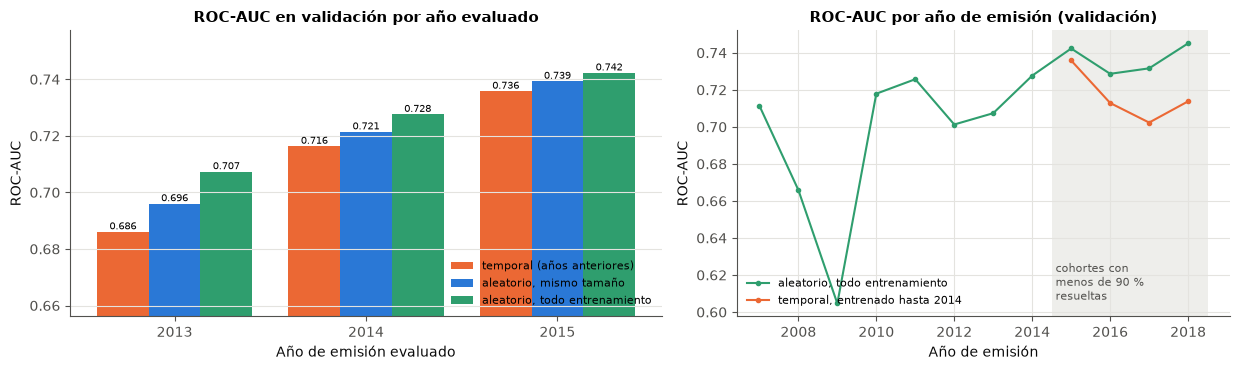

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 3.8), gridspec_kw={'width_ratios': [1.2, 1]})
tabla = resumen_estabilidad
ancho = 0.27
for j, (col, color) in enumerate((('temporal (años anteriores)', NARANJA), ('aleatorio, mismo tamaño', AZUL),
                                  ('aleatorio, todo entrenamiento', VERDE))):
    x = np.arange(len(tabla)) + (j - 1) * ancho
    ax1.bar(x, tabla[col], width=ancho, color=color, label=col)
    for xi, v in zip(x, tabla[col]):
        ax1.text(xi, v, f'{v:.3f}', ha='center', va='bottom', fontsize=7)
ax1.set_xticks(np.arange(len(tabla)), tabla.index)
ax1.set_ylim(tabla.iloc[:, :3].min().min() - 0.03, tabla.iloc[:, :3].max().max() + 0.015)
ax1.set(title='ROC-AUC en validación por año evaluado', xlabel='Año de emisión evaluado', ylabel='ROC-AUC')
ax1.legend(frameon=False, fontsize=8, loc='lower right')
ax1.grid(axis='x', visible=False)

ax2.plot(auc_por_año.index, auc_por_año['ROC-AUC'], color=VERDE, marker='o', markersize=3,
         label='aleatorio, todo entrenamiento')
ax2.plot(horizonte.index, horizonte[f'ROC-AUC temporal (≤ {AÑO_CORTE})'], color=NARANJA, marker='o', markersize=3,
         label=f'temporal, entrenado hasta {AÑO_CORTE}')
ax2.axvspan(AÑO_CORTE + 0.5, auc_por_año.index.max() + 0.5, color=REJILLA, alpha=0.6, linewidth=0)
ax2.text(AÑO_CORTE + 0.6, auc_por_año['ROC-AUC'].min(), 'cohortes con\nmenos de 90 %\nresueltas', fontsize=8,
         color=TINTA_2, va='bottom')
ax2.set(title='ROC-AUC por año de emisión (validación)', xlabel='Año de emisión', ylabel='ROC-AUC')
ax2.legend(frameon=False, fontsize=8, loc='lower left')
fig.tight_layout()
guardar(fig, 'temporal_estabilidad.png')
plt.show()

**Lectura:**

- **Entrenar con el pasado cuesta poco al año siguiente.** Frente a un modelo aleatorio del mismo tamaño, el temporal pierde 0.010 de ROC-AUC en 2013, 0.005 en 2014 y 0.0035 en 2015. La pérdida se reduce a medida que hay más historia para entrenar.
- **El modelo temporal hasta 2014 obtiene 0.7358 en 2015**, prácticamente lo mismo que el modelo final en toda la validación (0.7334). Es la prueba más realista: entrenado solo con cohortes maduras y evaluado en el año siguiente, el modelo mantiene su desempeño.
- **Tener más datos pesa tanto como el tiempo.** Pasar de la muestra del mismo tamaño a todo el entrenamiento suma entre 0.003 y 0.011, del mismo orden que la pérdida temporal.
- **La pérdida crece con el horizonte.** Evaluado 2, 3 y 4 años después, el modelo hasta 2014 queda 0.016 (2016), 0.029 (2017) y 0.031 (2018) por debajo del modelo aleatorio en los mismos préstamos. Esas cohortes son inmaduras, así que los valores absolutos no representan el desempeño real, pero la comparación es justa: ambos modelos se evalúan con los mismos préstamos. Parte de la caída se explica porque el modelo temporal no tiene las 13 variables del buró que Lending Club empezó a registrar en 2015–2016 (entrena con 48 numéricas en vez de 61) y porque usa un tercio de los préstamos (290,773 frente a 862,757; según la tabla anterior, eso vale entre 0.003 y 0.011).

## 6. Conclusiones

1. **Madurez:** las cohortes 2007–2013 están completas; 2014 tiene 94.7 % de préstamos resueltos y 2015 89.2 % (100 % a 36 meses, 67 % a 60 meses). Desde 2016 menos del 70 % está resuelto y los resueltos son una submuestra sesgada. **Corte cronológico: 2014.**
2. **Estabilidad temporal:** el gradient boosting del modelo final, entrenado solo con cohortes hasta 2014, obtiene **ROC-AUC 0.7358 en 2015**, frente a 0.7394 de un modelo del mismo tamaño con partición aleatoria (−0.0035). Con ventana expansiva, la pérdida al año siguiente es de 0.004 a 0.010 de ROC-AUC.
3. **La partición aleatoria es algo optimista, pero poco:** las métricas del modelo final (ROC-AUC 0.7354 en prueba) sobrestiman en menos de 0.01 lo que se obtendría al aplicarlo al año siguiente. A 2–4 años la pérdida llega a 0.016–0.031, así que el modelo debería reentrenarse al menos una vez al año y vigilar su desempeño por cohorte.
4. **No se cambia la partición del proyecto.** Las conclusiones del modelo final se mantienen; esta comprobación acota cuánto pueden empeorar en producción.

**Limitaciones:**

- Las cohortes 2016–2018 (38.5 % de los préstamos resueltos) son inmaduras y están en entrenamiento, validación y prueba de la partición aleatoria. Los valores absolutos del horizonte de 2 a 4 años no deben leerse como desempeño esperado.
- No se usa el conjunto de prueba: todas las métricas son de validación.
- Una sola semilla por experimento. Las diferencias de 0.003–0.005 están cerca del ruido; las de 0.010 en adelante son consistentes en todos los años.